# Step 6 · Traditional Batch Data Warehouse (PostgreSQL) · live demo

**Architecture (brief §2A):** `Raw source → Python curation (Step 2) → Staging → ETL → Dimensional warehouse → OLAP → Power BI`

| Piece | Where |
|---|---|
| PostgreSQL 16 in Docker | `05_dw_batch/docker-compose.yml` (port 5433) |
| Schema: staging + fact constellation | `sql/01_create_schema.sql` |
| Static dimensions (Date, Time, Characteristic) | `sql/02_static_dimensions.sql` |
| Per-batch load: DQ rules → dimension lookup / new members → fact → monthly fact | `sql/03_load_batch.sql` |
| Foreign keys + indexes (after the bulk load) | `sql/04_constraints_indexes.sql` |
| Historical analytical queries | `sql/05_analytical_queries.sql` |
| ETL program | `etl/etl_batch.py` |

**Incremental scenario (brief §10):** the **initial load** covers 1 Jan 2024 – 30 Nov 2025. **December 2025 is held back** as "newly arrived data" and loaded later **without rebuilding** the warehouse:
`New period → Staging → DQ rules → existing dimension lookup → insert new dimension members → fact load → validation`

**Before running:** `docker compose -f 05_dw_batch/docker-compose.yml up -d` (the notebook starts it if needed).

In [1]:
import sys, subprocess, time, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
ROOT = Path.cwd().resolve()
for p in [ROOT, *ROOT.parents]:
    if (p / '05_dw_batch' / 'etl').exists(): ROOT = p; break
sys.path.insert(0, str(ROOT / '05_dw_batch' / 'etl'))
import etl_batch as etl
OUT = ROOT / '05_dw_batch'; FIG, TAB = OUT / 'figures', OUT / 'tables'; FIG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid'); pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)
def save_tab(df, n, index=False): df.to_csv(TAB / f'B{n}.csv', index=index); return df
def save_fig(n): plt.tight_layout(); plt.savefig(FIG / f'B{n}.png', dpi=130, bbox_inches='tight'); plt.show()
r = subprocess.run(['docker', 'compose', '-f', str(OUT / 'docker-compose.yml'), 'up', '-d', '--wait'], capture_output=True, text=True)
print(r.stdout[-300:] or r.stderr[-300:])
print(subprocess.run(['docker', 'ps', '--filter', 'name=wq_batch_dw', '--format', '{{.Names}}  {{.Status}}  {{.Ports}}'], capture_output=True, text=True).stdout)

 Container wq_batch_dw Running 
 Container wq_batch_dw Waiting 
 Container wq_batch_dw Healthy 



wq_batch_dw  Up 23 seconds (healthy)  0.0.0.0:5433->5432/tcp, [::]:5433->5432/tcp



## 1 · Create the warehouse (staging + dimensions + facts)
Drops and recreates the `stg` and `dw` schemas, then loads the **static dimensions**: every calendar day (DimDate), 24 hours + "Not Reported" (DimTime), and the 6 parameters with their documented thresholds (DimCharacteristic).

In [2]:
con = etl.reset()
display(etl.table_counts(con))
display(etl.q(con, 'SELECT * FROM dw.dim_characteristic'))
display(etl.q(con, "SELECT * FROM dw.dim_date WHERE date_key IN (20240101, 20240706, 20251231)"))

Schema created and static dimensions loaded in 0.9s


,table_name,rows
0,dim_date,731
1,dim_time,25
2,dim_monitoring_location,0
3,dim_characteristic,6
4,dim_organization_method,0
5,fact_water_quality_result,0
6,fact_site_monthly_water_quality,0


,characteristic_key,characteristic_name,short_name,parameter_group,standard_unit,exceedance_rule,high_risk_rule,threshold_source
0,1,"Temperature, water",Temperature,Physical,°C,> 28 °C,> 32 °C,Project threshold (aquatic-life heat stress)
1,2,Dissolved oxygen (DO),Dissolved oxygen,Chemical,mg/L,< 5 mg/L,< 2 mg/L (hypoxia),EPA aquatic-life DO criteria
2,3,pH,pH,Chemical,pH units,< 6.5 or > 9.0,< 6.0 or > 9.5,"EPA national criterion 6.5–9, margin = project"
3,4,Turbidity,Turbidity,Physical,NTU,> 25 NTU,> 100 NTU,Project threshold
4,5,Conductivity,Conductivity,Physical,µS/cm,"> 1,500 µS/cm","> 3,000 µS/cm",Project threshold
5,6,Nitrate,Nitrate,Nutrient,mg/L as N,> 10 mg/L as N,> 20 mg/L as N,"EPA drinking-water MCL 10 mg/L, 20 = project"


,date_key,full_date,day_of_month,day_name,day_of_week,is_weekend,week_of_year,month,month_name,year_month,quarter,year,season
0,20240101,2024-01-01,1,Monday,1,False,1,1,January,2024-01,1,2024,Winter
1,20240706,2024-07-06,6,Saturday,6,True,27,7,July,2024-07,3,2024,Summer
2,20251231,2025-12-31,31,Wednesday,3,False,1,12,December,2025-12,4,2025,Winter


## 2 · Initial load (1 Jan 2024 – 30 Nov 2025)
1. **Extract:** analysis-ready single readings for the period are read from the curated Parquet file and bulk-copied (`COPY`) into `stg.wq_results`.
2. **Data-quality rules:** rows with a missing key, value or date, an unknown parameter, or a date outside the study period are rejected.
3. **Dimensions:** every new site → `dim_monitoring_location` (state, region, coordinates, water type); every new organization/method combination → `dim_organization_method`. Each gets a **surrogate key**.
4. **Fact:** each staged row looks up its 5 surrogate keys and is inserted into `fact_water_quality_result`.
5. **Monthly fact:** `fact_site_monthly_water_quality` is built **from the detail fact** (site × parameter × month).
6. **Constraints and indexes** are added *after* the bulk load (much faster), and from then on they protect every later load.

In [3]:
s1, t1 = etl.load(*etl.INITIAL, con=con)
display(pd.Series(s1, name='Initial load').to_frame())
display(pd.Series(t1, name='seconds').to_frame())
display(etl.table_counts(con))

,Initial load
load_batch_id,1
load_mode,initial
period_start,2024-01-01
period_end,2025-11-30
staged_rows,3748844
rejected_rows,0
new_locations,49218
new_org_methods,926
fact_rows_inserted,3748844
monthly_rows,979618


,seconds
1. Extract → staging,94.9
"2. DQ rules, dimensions, facts, monthly fact",203.7
3. Constraints + indexes (after bulk load),47.1


,table_name,rows
0,dim_date,731
1,dim_time,25
2,dim_monitoring_location,49218
3,dim_characteristic,6
4,dim_organization_method,926
5,fact_water_quality_result,3748844
6,fact_site_monthly_water_quality,979618


## 3 · Validation and reconciliation after the initial load
Referential integrity (no fact points to a missing dimension row), no duplicate results, and reconciliation of counts and value sums between staging, the warehouse, and the monthly fact.
*(The check against all curated analysis-ready rows is expected to FAIL here, because December 2025 is deliberately not loaded yet.)*

In [4]:
v1 = etl.validate(con); display(save_tab(v1, '03_validation_after_initial'))

,Check,Warehouse,Expected,Status
0,Fact rows = staged rows (all batches),3748844,3748844,PASS
1,Fact rows = curated analysis-ready rows,3748844,3772033,FAIL
2,Orphan date_key,0,0,PASS
3,Orphan location_key,0,0,PASS
4,Orphan characteristic_key,0,0,PASS
5,Orphan org_method_key,0,0,PASS
6,Orphan time_key,0,0,PASS
7,Duplicate result_id in fact,0,0,PASS
8,Monthly fact sample_count = detail fact rows,3748844,3748844,PASS
9,Monthly fact exceedances = detail fact exceeda...,291178,291178,PASS


## 4 · Historical analytical queries with execution time
Each query from `sql/05_analytical_queries.sql` is run 3 times; the median time is reported. The last query answers the monthly trend from the **aggregate fact** instead of the 3.7M-row detail fact, to show the benefit of the fact constellation.

In [5]:
tq1, res1 = etl.queries(repeat=3, con=con)
display(save_tab(tq1, '04_query_times_initial'))
for n in ['Q3_worst_sites', 'Q6_exceedance_by_region', 'Q8_water_type']:
    print(n); display(res1[n].head(10))

,Query,Question,Rows returned,Median ms,Min ms
0,Q1_monthly_trend,"Q1: results, sites and exceedance rate per month",23,5414.1,5300.7
1,Q2_site_comparison,Q2: median value per parameter for sites with ...,6,3171.4,2867.5
2,Q3_worst_sites,Q3: sites with the highest DO exceedance rate ...,10,1959.9,1954.2
3,Q4_seasonal,Q4: seasonal median and exceedance rate per pa...,24,4562.9,4172.9
4,Q6_exceedance_by_region,Q6: exceedances and high-risk results by regio...,34,1110.8,1103.9
5,Q7_org_coverage,"Q7: organization coverage (sites, parameters, ...",15,8788.4,8116.3
6,Q8_water_type,Q8: median value by location (water) type and ...,17,1554.2,1271.9
7,M1_monthly_fact_trend,Same monthly trend answered from the aggregate...,23,244.5,193.5


Q3_worst_sites


,site_id,state,results,exceedance_pct,median_do
0,21FLDADE_WQX-TM05,Florida,51,100.0,0.75
1,21FLDADE_WQX-TM07A,Florida,51,100.0,1.14
2,21FLDADE_WQX-SP08,Florida,51,100.0,0.77
3,21FLDADE_WQX-LR08,Florida,51,100.0,2.82
4,21FLDADE_WQX-LR07,Florida,51,100.0,2.50
5,21FLDADE_WQX-TM06,Florida,51,100.0,0.79
6,21FLDADE_WQX-MW13,Florida,51,100.0,1.73
7,21FLDADE_WQX-LR06,Florida,51,100.0,2.54
8,21FLDADE_WQX-LR05,Florida,51,100.0,2.48
9,21FLDADE_WQX-WC02,Florida,51,100.0,1.93


Q6_exceedance_by_region


,region,short_name,results,exceedances,exceedance_pct,high_risk
0,Unknown,Conductivity,138,120,86.96,120
1,Territory,Temperature,4091,2880,70.40,49
2,South,Dissolved oxygen,269221,63366,23.54,23253
3,Unknown,Turbidity,3182,641,20.14,225
4,Northeast,pH,42511,8355,19.65,2600
5,South,Temperature,277087,52572,18.97,3490
6,Midwest,Dissolved oxygen,269484,51016,18.93,32671
7,West,Turbidity,56588,8528,15.07,3298
8,Unknown,Dissolved oxygen,1089,142,13.04,20
9,South,pH,281122,34683,12.34,13322


Q8_water_type


,water_type,short_name,results,median_value
0,Groundwater,Conductivity,1048,637.50
1,Ocean Water,Conductivity,7,42440.00
2,Surface Water,Conductivity,10043,189.10
3,Groundwater,Dissolved oxygen,5369,0.55
4,Ocean Water,Dissolved oxygen,1318,10.76
5,Surface Water,Dissolved oxygen,229846,7.06
6,Groundwater,Nitrate,707,2.36
7,Surface Water,Nitrate,11324,0.38
8,Groundwater,Temperature,6142,22.50
9,Ocean Water,Temperature,2451,11.00


## 5 · Incremental load: December 2025 arrives
Exactly the same ETL runs for **one new month only**. The existing 3.7M facts are **not touched or rebuilt**. Existing sites and organizations are **looked up** by their natural key; only **new** ones get new surrogate keys. Only the December rows of the monthly fact are rebuilt.

In [6]:
before = etl.table_counts(con).set_index('table_name').rows
s2, t2 = etl.load(*etl.INCREMENTAL, con=con)
after = etl.table_counts(con).set_index('table_name').rows
display(pd.Series(s2, name='Incremental load').to_frame()); display(pd.Series(t2, name='seconds').to_frame())
delta = pd.DataFrame({'Before': before, 'After': after}); delta['Added'] = delta.After - delta.Before
display(save_tab(delta, '05_incremental_delta', index=True))
print('New sites first seen in December 2025:')
display(etl.q(con, '''SELECT site_id, state, region, water_type FROM dw.dim_monitoring_location WHERE first_load_batch = 2 ORDER BY state LIMIT 10'''))
log = etl.q(con, 'SELECT * FROM dw.etl_load_log ORDER BY load_batch_id'); display(save_tab(log, '05_etl_load_log'))

,Incremental load
load_batch_id,2
load_mode,incremental
period_start,2025-12-01
period_end,2025-12-31
staged_rows,23189
rejected_rows,0
new_locations,53
new_org_methods,2
fact_rows_inserted,23189
monthly_rows,995875


,seconds
1. Extract → staging,5.8
"2. DQ rules, dimensions, facts, monthly fact",9.1


,Before,After,Added
table_name,,,
dim_date,731,731,0
dim_time,25,25,0
dim_monitoring_location,49218,49271,53
dim_characteristic,6,6,0
dim_organization_method,926,928,2
fact_water_quality_result,3748844,3772033,23189
fact_site_monthly_water_quality,979618,995875,16257


New sites first seen in December 2025:


,site_id,state,region,water_type
0,AWW_WQX-aww_2712,Alabama,South,Not Reported
1,AWW_WQX-aww_0716,Alabama,South,Not Reported
2,AWW_WQX-aww_0793,Alabama,South,Not Reported
3,AZDEQ_SW-BWBWR046.42_102307,Arizona,West,Surface Water
4,AZDEQ_SW-BWBWR038.52_102316,Arizona,West,Surface Water
5,AZDEQ_GW-55-510802_83310,Arizona,West,Groundwater
6,AZDEQ_SW-BWALA-A_101350,Arizona,West,Surface Water
7,AZDEQ_GW-55-618049_83311,Arizona,West,Groundwater
8,AZDEQ_SW-MGNWR043.60_111704,Arizona,West,Surface Water
9,AZDEQ_SW-SCBCN001.40_105518,Arizona,West,Surface Water


,load_batch_id,load_mode,period_start,period_end,staged_rows,rejected_rows,new_locations,new_org_methods,fact_rows_inserted,monthly_rows,started_at,finished_at,seconds
0,1,initial,2024-01-01,2025-11-30,3748844,0,49218,926,3748844,979618,2026-11-19 21:34:58.106434,2026-11-19 21:40:52.239373,354.1
1,2,incremental,2025-12-01,2025-12-31,23189,0,53,2,23189,995875,2026-11-19 21:42:52.832018,2026-11-19 21:43:08.580812,15.7


## 6 · Validation after the incremental load
All checks must now PASS, including **warehouse rows = all curated analysis-ready rows** (Step 2), which proves the initial + incremental loads together are complete.

In [7]:
v2 = etl.validate(con); display(save_tab(v2, '06_validation_after_incremental'))
print('ALL CHECKS PASS' if (v2.Status == 'PASS').all() else 'SOME CHECKS FAILED')

,Check,Warehouse,Expected,Status
0,Fact rows = staged rows (all batches),3772033,3772033,PASS
1,Fact rows = curated analysis-ready rows,3772033,3772033,PASS
2,Orphan date_key,0,0,PASS
3,Orphan location_key,0,0,PASS
4,Orphan characteristic_key,0,0,PASS
5,Orphan org_method_key,0,0,PASS
6,Orphan time_key,0,0,PASS
7,Duplicate result_id in fact,0,0,PASS
8,Monthly fact sample_count = detail fact rows,3772033,3772033,PASS
9,Monthly fact exceedances = detail fact exceeda...,292571,292571,PASS


ALL CHECKS PASS


## 7 · Queries after the incremental load, and load summary charts

,Query,Median ms (initial),Median ms (after incremental)
0,Q1_monthly_trend,5414.1,6555.5
1,Q2_site_comparison,3171.4,3358.4
2,Q3_worst_sites,1959.9,1525.9
3,Q4_seasonal,4562.9,4643.7
4,Q6_exceedance_by_region,1110.8,1217.0
5,Q7_org_coverage,8788.4,8660.7
6,Q8_water_type,1554.2,1710.2
7,M1_monthly_fact_trend,244.5,222.6


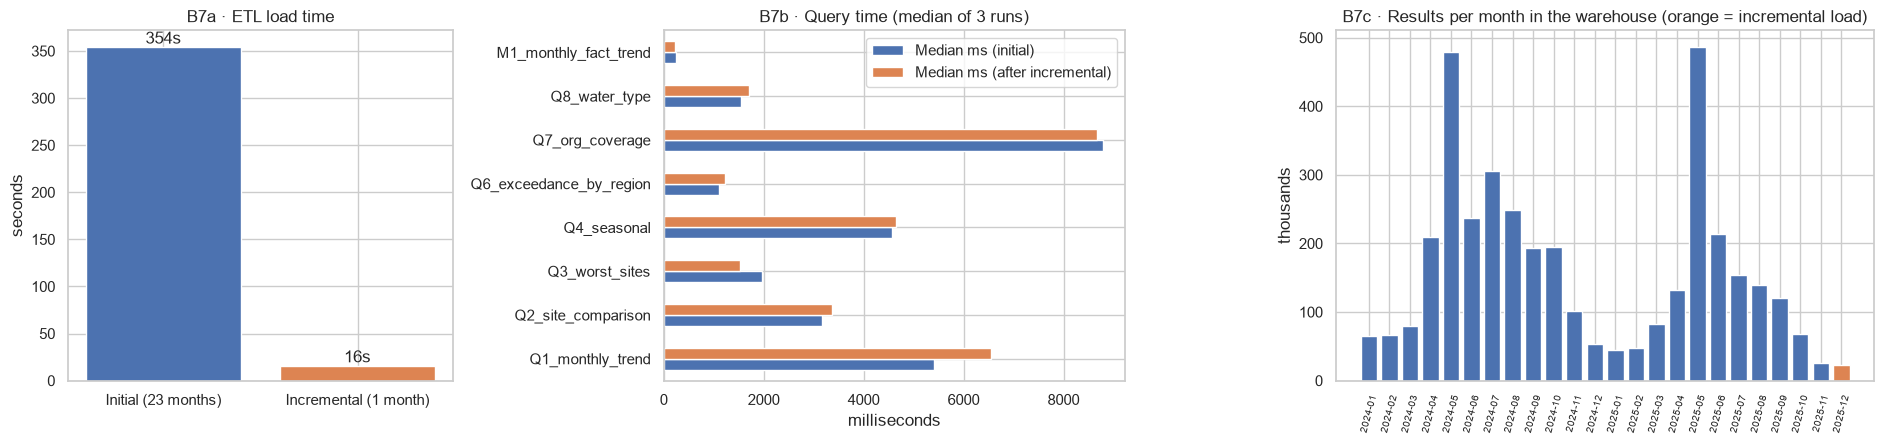

In [8]:
tq2, res2 = etl.queries(repeat=3, con=con)
tq = tq1[['Query', 'Median ms']].merge(tq2[['Query', 'Median ms']], on='Query', suffixes=(' (initial)', ' (after incremental)'))
display(save_tab(tq, '07_query_times'))
m = res2['Q1_monthly_trend']; m['results'] = m.results.astype(int)
fig, axes = plt.subplots(1, 3, figsize=(19, 4.6), gridspec_kw={'width_ratios': [1, 1.2, 1.4]})
lt = pd.DataFrame({'Initial (23 months)': [s1['seconds']], 'Incremental (1 month)': [s2['seconds']]}).T
axes[0].bar(lt.index, lt[0], color=['#4C72B0', '#DD8452']); [axes[0].text(i, v_, f'{v_:.0f}s', ha='center', va='bottom') for i, v_ in enumerate(lt[0])]
axes[0].set(title='B7a · ETL load time', ylabel='seconds')
d = tq.set_index('Query')
d.plot(kind='barh', ax=axes[1], color=['#4C72B0', '#DD8452']); axes[1].set(title='B7b · Query time (median of 3 runs)', xlabel='milliseconds', ylabel='')
axes[2].bar(m.year_month, m.results / 1e3, color=['#DD8452' if x == '2025-12' else '#4C72B0' for x in m.year_month])
axes[2].set(title='B7c · Results per month in the warehouse (orange = incremental load)', ylabel='thousands'); axes[2].tick_params(axis='x', rotation=75, labelsize=7.5)
save_fig('07_load_and_query_summary')

**Why these charts:** load time compares the full and incremental ETL runs; query times show how fast the warehouse answers the business questions; the monthly bars show that the incremental month joined the existing history without a rebuild.

**🔎 Inference (B7): loads, queries and the incremental scenario**
- **Initial load:** 3,748,844 results (Jan 2024 – Nov 2025) with 49,218 sites and 926 organization/method combinations, in **354 s**. That includes staging (bulk COPY), the data-quality rules, dimension and fact loading, the monthly fact, and creating the foreign keys and indexes.
- **Incremental load (December 2025):** 23,189 new results in **16 s**, about **23× faster** than the initial load, **without rebuilding anything**.
  - The existing sites and organizations were *looked up* by their natural keys.
  - Only **53 genuinely new sites** and **2 new organization/method combinations** got new surrogate keys.
  - Only the December rows of the monthly fact were rebuilt.
  - **0 rows were rejected** by the data-quality rules, as expected, because Step 2 already cleaned the data. The rules stay in place for future batches.
- **Validation: all 11 checks PASS** (11/11):
  - no orphan keys and no duplicate results
  - warehouse rows = **all 3,772,033 curated analysis-ready rows**
  - monthly-fact totals = detail-fact totals (rows and exceedances)
  - the sum of all values equals staging to the last unit
- **Query performance:** the 8 analytical queries over 3.77M facts run in about **1–7 s** each.
  - The monthly trend answered from the **aggregate fact takes 223 ms vs 6,556 ms** from the detail fact, **29× faster**. That is measured evidence for choosing the **fact constellation** (Step 5).
  - Median-based queries (Q2, Q4) are the slowest because a median must sort values. Times barely change after the incremental load (+0.6% rows), showing the design scales smoothly.
- **The chart of results per month** shows December 2025 (orange) joined onto the existing history as a normal month.

## 8 · Warehouse size

In [9]:
sz = etl.q(con, '''SELECT relname AS table_name, pg_size_pretty(pg_total_relation_size(c.oid)) AS total_size,
                          pg_total_relation_size(c.oid) AS bytes
                   FROM pg_class c JOIN pg_namespace n ON n.oid = c.relnamespace
                   WHERE n.nspname = 'dw' AND c.relkind = 'r' ORDER BY bytes DESC''')
display(save_tab(sz, '08_table_sizes'))

,table_name,total_size,bytes
0,fact_water_quality_result,719 MB,753737728
1,fact_site_monthly_water_quality,117 MB,122454016
2,dim_monitoring_location,8616 kB,8822784
3,dim_organization_method,272 kB,278528
4,dim_date,160 kB,163840
5,dim_characteristic,48 kB,49152
6,etl_load_log,32 kB,32768
7,dim_time,32 kB,32768


**🔎 Inference (B8): warehouse size**
- The detail fact (`fact_water_quality_result`, 3.77M rows, including its indexes) is **719 MB**, the monthly fact is **117 MB**, and every dimension together is only a few MB.
- So the **fact table is over 95% of the warehouse**. Making the dimensions smaller by snowflaking would save almost nothing, which confirms the Step 5 choice of simple star dimensions.
- The whole warehouse fits comfortably on a laptop. Moving to a distributed design (Citus, Step 7) is about **parallel query speed and scaling to more data**, not about storage capacity at this size.